<a href="https://colab.research.google.com/github/attaboatengsr/data620/blob/main/project2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Network Analysis Solution: 2-Node Bipartite Dataset & The Island Method
This notebook loads the MovieLens dataset, builds and verifies a 2-node bipartite network, applies the Island Method to reduce the network size, and visualizes the reduction curve.

In [41]:
import os
import urllib.request
import zipfile
import pandas as pd
import requests
import urllib.request
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt
import ssl

In [42]:
import urllib.request
import zipfile
import ssl

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
zip_path = "ml-latest-small.zip"

# Create an unverified SSL context to bypass verification errors
context = ssl._create_unverified_context()

# Downloading the dataset using the unverified context
with urllib.request.urlopen(url, context=context) as response, open(zip_path, 'wb') as out_file:
    out_file.write(response.read())

# Extracting files
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

In [43]:
# Load CSVs from the extracted folder
movies_df = pd.read_csv("ml-latest-small/movies.csv")
ratings_df = pd.read_csv("ml-latest-small/ratings.csv")

print(f"Loaded {len(movies_df)} movies and {len(ratings_df)} ratings.")

# Display samples
display(movies_df.head())
display(ratings_df.head())

Loaded 9742 movies and 100836 ratings.


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [44]:
# Group ratings by movieId
movie_stats = ratings_df.groupby('movieId').agg(
    mean_rating=('rating', 'mean'),
    rating_count=('rating', 'count')
).reset_index()

# Merge metadata with statistics
merged_df = pd.merge(movies_df, movie_stats, on='movieId')

# Preview top rows by rating count
merged_df.sort_values(by='rating_count', ascending=False).head()

,movieId,title,genres,mean_rating,rating_count
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164134,329
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429022,317
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197068,307
510,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.161290,279
1938,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192446,278


In [46]:

top_movies = merged_df[merged_df['rating_count'] >= 100]

# Sort by highest average rating
top_movies_sorted = top_movies.sort_values(by='mean_rating', ascending=False).head(10)

# Clean up formatting for display
display_df = top_movies_sorted[['title', 'genres', 'mean_rating', 'rating_count']].copy()
display_df['mean_rating'] = display_df['mean_rating'].round(2)

display(display_df.reset_index(drop=True))

,title,genres,mean_rating,rating_count
0,"Shawshank Redemption, The (1994)",Crime|Drama,4.43,317
1,"Godfather, The (1972)",Crime|Drama,4.29,192
2,Fight Club (1999),Action|Crime|Drama|Thriller,4.27,218
3,"Godfather: Part II, The (1974)",Crime|Drama,4.26,129
4,"Departed, The (2006)",Crime|Drama|Thriller,4.25,107
5,Goodfellas (1990),Crime|Drama,4.25,126
6,Casablanca (1942),Drama|Romance,4.24,100
7,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.24,149
8,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.24,204
9,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.23,142


In [47]:
# 2. Filter for popular movies (e.g., at least 50 ratings) to reduce noise
movie_counts = ratings_df['movieId'].value_counts()
popular_movie_ids = movie_counts[movie_counts >= 100].index
filtered_ratings = ratings_df[ratings_df['movieId'].isin(popular_movie_ids)]

# 3. Create a User-Movie pivot table (Rows: Users, Columns: Movies, Values: 1 if rated else 0)
user_movie_matrix = filtered_ratings.pivot_table(
    index='userId',
    columns='movieId',
    values='rating',
    aggfunc=lambda x: 1
).fillna(0)

print(f"Matrix shape: {user_movie_matrix.shape} (Users x Popular Movies)")

Matrix shape: (597, 138) (Users x Popular Movies)


In [48]:
# Calculate co-occurrence matrix (dot product of transposed matrix)
co_occurrence = np.dot(user_movie_matrix.T, user_movie_matrix)

# Convert co-occurrence matrix to a DataFrame with movieIds as index/columns
co_df = pd.DataFrame(co_occurrence, index=user_movie_matrix.columns, columns=user_movie_matrix.columns)

# Build a NetworkX graph where edges represent shared user ratings (threshold >= 15 shared users)
threshold = 15
G = nx.Graph()

movie_ids = user_movie_matrix.columns
for i in range(len(movie_ids)):
    for j in range(i + 1, len(movie_ids)):
        shared_users = co_df.iloc[i, j]
        if shared_users >= threshold:
            G.add_edge(movie_ids[i], movie_ids[j], weight=shared_users)

# Compute Degree Centrality
degree_cent = nx.degree_centrality(G)

# Map back to movie titles
centrality_df = pd.DataFrame(list(degree_cent.items()), columns=['movieId', 'degree_centrality'])
centrality_df = pd.merge(movies_df, centrality_df, on='movieId')

# Get top 10 movies by degree centrality
top_central_movies = centrality_df.sort_values(by='degree_centrality', ascending=False).head(10)

print("Top 10 Movies by Degree Centrality in the Co-Rating Network:")
display(top_central_movies[['title', 'genres', 'degree_centrality']].reset_index(drop=True))

Top 10 Movies by Degree Centrality in the Co-Rating Network:


,title,genres,degree_centrality
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,Jumanji (1995),Adventure|Children|Fantasy,1.0
2,Heat (1995),Action|Crime|Thriller,1.0
3,GoldenEye (1995),Action|Adventure|Thriller,1.0
4,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller,1.0
5,Babe (1995),Children|Drama,1.0
6,Clueless (1995),Comedy|Romance,1.0
7,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,1.0
8,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,1.0
9,Braveheart (1995),Action|Drama|War,1.0


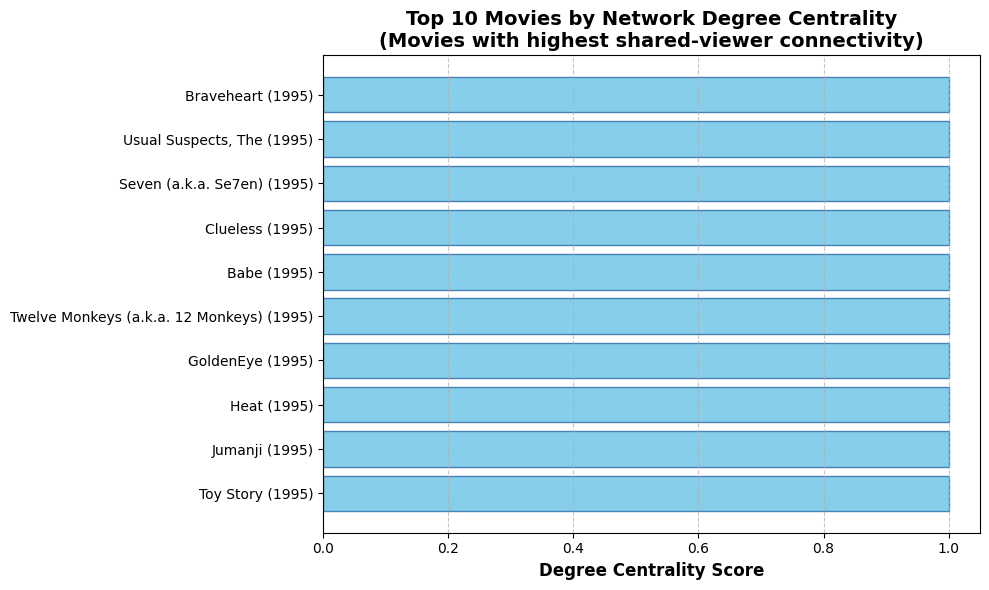

In [49]:
plt.figure(figsize=(10, 6))

# Sort ascending for horizontal bar chart layout
plot_data = top_central_movies.sort_values(by='degree_centrality', ascending=True)

# Clean up movie titles for better label readability (removing year if desired, or keeping it)
y_pos = np.arange(len(plot_data))
plt.barh(y_pos, plot_data['degree_centrality'], color='skyblue', edgecolor='steelblue')

plt.yticks(y_pos, plot_data['title'], fontsize=10)
plt.xlabel('Degree Centrality Score', fontsize=12, fontweight='bold')
plt.title('Top 10 Movies by Network Degree Centrality\n(Movies with highest shared-viewer connectivity)', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

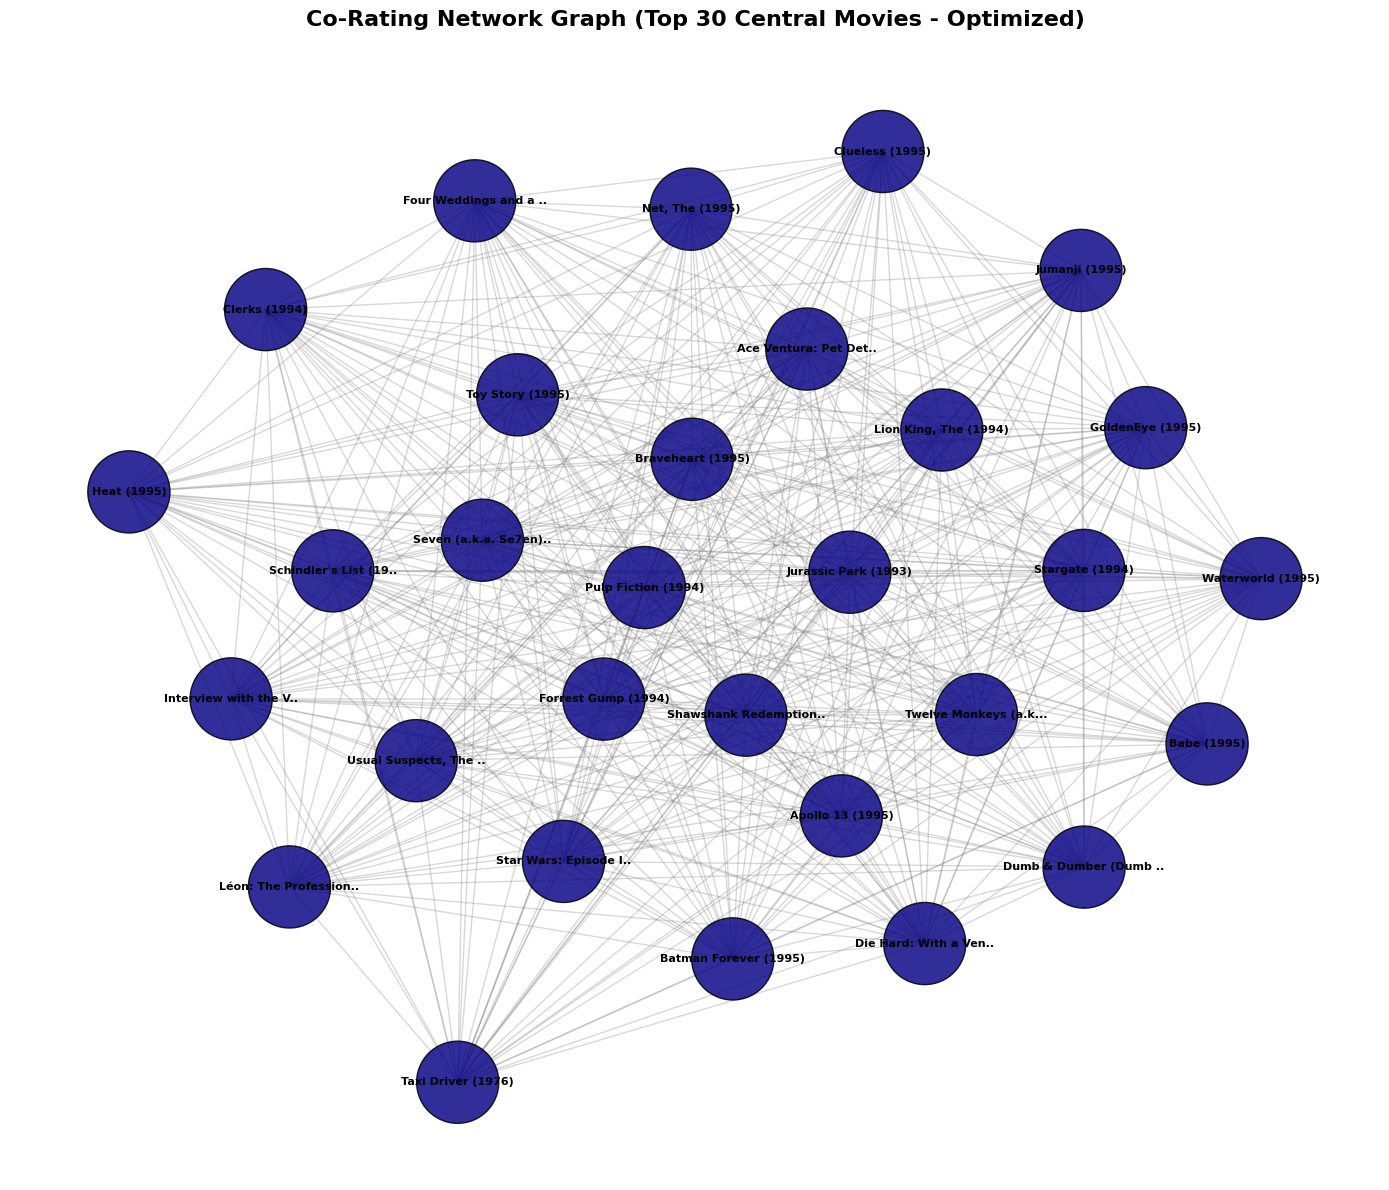

In [52]:
plt.figure(figsize=(14, 12))

# 1. Select the top 30 movies by degree centrality
top_n_nodes = centrality_df.sort_values(by='degree_centrality', ascending=False).head(30)['movieId'].tolist()
subgraph = G.subgraph(top_n_nodes)

# 2. Increase 'k' to spread out nodes and prevent crowding
pos = nx.spring_layout(subgraph, k=0.8, iterations=100, seed=42)

# 3. Scale node sizes down so they don't overlap as much
node_sizes = [degree_cent[node] * 3500 for node in subgraph.nodes()]
node_colors = [degree_cent[node] for node in subgraph.nodes()]

# 4. Draw edges and nodes with slight transparency
nx.draw_networkx_edges(subgraph, pos, width=1.0, alpha=0.3, edge_color='gray')
nx.draw_networkx_nodes(
    subgraph, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.plasma,
    alpha=0.85,
    edgecolors='black' # Adds a clean border around nodes
)

# 5. Map node IDs to short movie titles for labels
id_to_title = dict(zip(movies_df['movieId'], movies_df['title']))
labels = {node: id_to_title.get(node, str(node)) for node in subgraph.nodes()}

# Truncate long titles slightly for cleaner label rendering
short_labels = {k: (v[:20] + '..') if len(v) > 22 else v for k, v in labels.items()}

# Draw labels with dark text for contrast against the plasma colormap
nx.draw_networkx_labels(
    subgraph, pos,
    labels=short_labels,
    font_size=8,
    font_family='sans-serif',
    font_weight='bold'
)

plt.title('Co-Rating Network Graph (Top 30 Central Movies - Optimized)', fontsize=16, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

Movies with higher degree centrality shared viewers across a massive portion of the other films in the dataset.